# 01 · Data exploration: importing and standardising Serie A data

**Goal of this notebook:** turn 34 seasons of raw Serie A results from
[Football-Data.co.uk](https://www.football-data.co.uk/italym.php) into one clean,
consistent dataset that the rest of the project can rely on.

The pipeline logic lives in `src/` so it can be tested and reused; this notebook
calls those functions and shows *why* each step is needed.

| Step | Code |
|---|---|
| Download the raw season files | `src/data_loader.py` (`python -m src.data_loader`) |
| Read, standardise, combine and validate | `src/preprocessing.py` (`python -m src.preprocessing`) |

In [1]:
import csv
import io

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.config import FIGURES_DIR, RAW_DATA_DIR
from src.data_loader import season_label
from src.preprocessing import (
    COLUMN_SOURCES,
    build_matches,
    read_raw_season,
    save_matches,
    season_files,
    season_summary,
    validate_matches,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. The raw files

One CSV per season, named `I1_<season code>.csv` (`I1` is Football-Data's code for Serie A).
The files were collected over 30+ years, and their format changed a lot over that time.

In [2]:
def season_of(path):
    return season_label(path.stem.split("_")[1])


raw_overview = pd.DataFrame(
    [
        {
            "season": season_of(path),
            "file": path.name,
            "size_kb": round(path.stat().st_size / 1024, 1),
            "columns": read_raw_season(path).shape[1],
            "matches": read_raw_season(path).shape[0],
        }
        for path in season_files()
    ]
).set_index("season")

print(f"{len(raw_overview)} season files, {raw_overview['matches'].sum():,} matches in total")
raw_overview

34 season files, 11,826 matches in total


,file,size_kb,columns,matches
season,,,,
1993-94,I1_9394.csv,12.5,7,306
1994-95,I1_9495.csv,23.4,7,306
1995-96,I1_9596.csv,14.9,10,306
1996-97,I1_9697.csv,15.0,10,306
1997-98,I1_9798.csv,12.1,10,306
1998-99,I1_9899.csv,12.4,10,306
1999-00,I1_9900.csv,14.7,10,306
2000-01,I1_0001.csv,29.1,25,306
2001-02,I1_0102.csv,31.0,28,306


The number of columns grows from about 10 in the 1990s to over 100 today, as Football-Data added
match statistics (shots, corners, cards) and odds from more and more bookmakers.
Getting from this to one table needs four fixes.

### Quirk 1: ragged rows

In some older files, rows have **more or fewer fields than the header**. Read naively with
`pd.read_csv`, those rows cause errors or get skipped, and matches are silently lost:

In [3]:
for code in ["0304", "0405"]:
    path = RAW_DATA_DIR / f"I1_{code}.csv"
    naive = pd.read_csv(path, on_bad_lines="skip").dropna(how="all")
    robust = read_raw_season(path)
    print(f"{season_label(code)}: naive pd.read_csv -> {len(naive)} matches, "
          f"read_raw_season -> {len(robust)} matches")

2003-04: naive pd.read_csv -> 194 matches, read_raw_season -> 306 matches
2004-05: naive pd.read_csv -> 300 matches, read_raw_season -> 380 matches


In [4]:
# The field count of each row in the 2003-04 file, compared with its header
with open(RAW_DATA_DIR / "I1_0304.csv", encoding="utf-8") as f:
    rows = list(csv.reader(f))
header_width = len(rows[0])
row_widths = pd.Series([len(r) for r in rows[1:]]).value_counts().sort_index()
print(f"Header has {header_width} fields; rows have:")
print(row_widths.rename("rows").to_string())

Header has 45 fields; rows have:
44    112
45     82
46     32
49     32
50     32
51     16


Checking the files shows the extra fields are **always empty**: the data still lines up with the
header. `read_raw_season` therefore reads with Python's `csv` module, pads or trims every row
to the header length, and raises an error if a row ever has real data past the last column.

### Quirk 2: two date formats

Up to 2017-18 dates are `dd/mm/yy`; from 2018-19 they are `dd/mm/yyyy`.

In [5]:
for code in ["1718", "1819"]:
    dates = read_raw_season(RAW_DATA_DIR / f"I1_{code}.csv")["Date"]
    print(f"{season_label(code)}: {dates.head(3).tolist()}")

2017-18: ['19/08/17', '19/08/17', '20/08/17']
2018-19: ['18/08/2018', '18/08/2018', '19/08/2018']


### Quirk 3: renamed columns

The same information sometimes appears under different names. The market-average odds were
`BbAvH` / `BbAvD` / `BbAvA` (from the BetBrain site) until 2018-19, then `AvgH` / `AvgD` / `AvgA`.

In [6]:
columns_by_season = {season_of(p): set(read_raw_season(p).columns) for p in season_files()}
renamed = pd.DataFrame(
    {name: {s: name in cols for s, cols in columns_by_season.items()} for name in ["BbAvH", "AvgH"]}
)
renamed[renamed.any(axis=1)].T

,2005-06,2006-07,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
BbAvH,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False
AvgH,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True


### Quirk 4: byte-order mark

Files from 2024-25 onwards start with an invisible UTF-8 byte-order mark (BOM). Without handling it,
the first column would be called `'\ufeffDiv'` instead of `'Div'`.

In [7]:
print((RAW_DATA_DIR / "I1_2425.csv").read_bytes()[:12])

b'\xef\xbb\xbfDiv,Date,'


## 2. Standardising into one schema

`standardise_season` maps every raw file onto the same columns with clear snake_case names.
Where Football-Data used several names for the same thing, the first available one is used.
Columns a season doesn't have (e.g. shots before 2005-06) are kept as missing values, so every
season has the same shape.

In [8]:
mapping = pd.DataFrame(
    [(name, " / ".join(sources)) for name, sources in COLUMN_SOURCES.items()],
    columns=["standard column", "raw Football-Data column(s)"],
)
mapping

,standard column,raw Football-Data column(s)
0,date,Date
1,time,Time
2,home_team,HomeTeam
3,away_team,AwayTeam
4,home_goals,FTHG / HG
5,away_goals,FTAG / AG
6,result,FTR / Res
7,ht_home_goals,HTHG
8,ht_away_goals,HTAG
9,ht_result,HTR


In [9]:
matches = build_matches()
print(f"{len(matches):,} matches x {matches.shape[1]} columns")
matches.head()

11,826 matches x 31 columns


,season,season_start,date,time,home_team,away_team,home_goals,away_goals,result,ht_home_goals,ht_away_goals,ht_result,referee,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_fouls,away_fouls,home_corners,away_corners,home_yellow_cards,away_yellow_cards,home_red_cards,away_red_cards,b365_home,b365_draw,b365_away,avg_odds_home,avg_odds_draw,avg_odds_away
0,1993-94,1993,1993-08-29,<NA>,Atalanta,Cagliari,5,2,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,1993-94,1993,1993-08-29,<NA>,Genoa,Roma,2,0,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,1993-94,1993,1993-08-29,<NA>,Inter,Reggiana,2,1,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,1993-94,1993,1993-08-29,<NA>,Juventus,Cremonese,1,0,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,1993-94,1993,1993-08-29,<NA>,Lazio,Foggia,0,0,D,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [10]:
matches.dtypes.to_frame("dtype").T

,season,season_start,date,time,home_team,away_team,home_goals,away_goals,result,ht_home_goals,ht_away_goals,ht_result,referee,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_fouls,away_fouls,home_corners,away_corners,home_yellow_cards,away_yellow_cards,home_red_cards,away_red_cards,b365_home,b365_draw,b365_away,avg_odds_home,avg_odds_draw,avg_odds_away
dtype,string,int64,datetime64[ns],string,string,string,Int64,Int64,string,Int64,Int64,string,string,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64


Goals and statistics use pandas' nullable `Int64` type, so a missing value (e.g. no shot data in
1995) stays *missing* instead of turning the whole column into floats or being filled with 0.
Odds are decimal (European) odds as `Float64`.

## 3. Validation

`validate_matches` checks the combined data before it is saved. It returns a list of problems,
and the script refuses to save if the list isn't empty. It checks that:

- no required field (season, date, teams, goals, result) is missing
- the result (`H` / `D` / `A`) agrees with the score, at full time and at half time
- no team plays itself, and no fixture appears twice in a season
- every date falls inside its season
- there are no negative counts and no odds of 1.0 or lower
- every completed season has `n × (n − 1)` matches, because each team hosts every other team once

In [11]:
issues = validate_matches(matches)
print("No issues found" if not issues else "\n".join(issues))

No issues found


In [12]:
summary = season_summary(matches)
summary

,teams,matches,first_match,last_match
season,,,,
1993-94,18,306,1993-08-29,1994-05-01
1994-95,18,306,1994-09-04,1995-06-04
1995-96,18,306,1995-08-27,1996-05-12
1996-97,18,306,1996-09-08,1997-06-01
1997-98,18,306,1997-08-31,1998-05-16
1998-99,18,306,1998-09-12,1999-05-23
1999-00,18,306,1999-08-28,2000-05-14
2000-01,18,306,2000-09-30,2001-06-17
2001-02,18,306,2001-08-25,2002-05-05


Serie A had **18 teams (306 matches)** up to 2003-04 and **20 teams (380 matches)** from 2004-05.
The 2026-27 season is still in progress, so it is excluded from the completeness check.
The 2019-20 season ran until August 2020 because of the COVID-19 break.

## 4. Which data is available in each season?

Results are available for all 34 seasons, but statistics and betting odds start later. This
determines which seasons each kind of model can be trained on.

In [13]:
coverage_groups = {
    "Full-time result": ["home_goals", "away_goals", "result"],
    "Half-time score": ["ht_home_goals", "ht_away_goals"],
    "Bet365 odds": ["b365_home", "b365_draw", "b365_away"],
    "Market-average odds": ["avg_odds_home", "avg_odds_draw", "avg_odds_away"],
    "Match statistics": [c for c in matches.columns if c.endswith(("shots", "shots_on_target", "fouls", "corners", "cards"))],
    "Kick-off time": ["time"],
    "Referee": ["referee"],
}

coverage = pd.DataFrame(
    {
        group: matches[cols].notna().all(axis=1).groupby(matches["season"]).mean()
        for group, cols in coverage_groups.items()
    }
).T  # rows = data group, columns = season

# Table view of the chart below: share of matches with the data (1.0 = all matches)
coverage.round(2)

season,1993-94,1994-95,1995-96,1996-97,1997-98,1998-99,1999-00,2000-01,2001-02,2002-03,2003-04,2004-05,2005-06,2006-07,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
Full-time result,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Half-time score,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Bet365 odds,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.99,0.92,0.98,0.99,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0
Market-average odds,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Match statistics,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.96,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Kick-off time,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Referee,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,1.00,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0


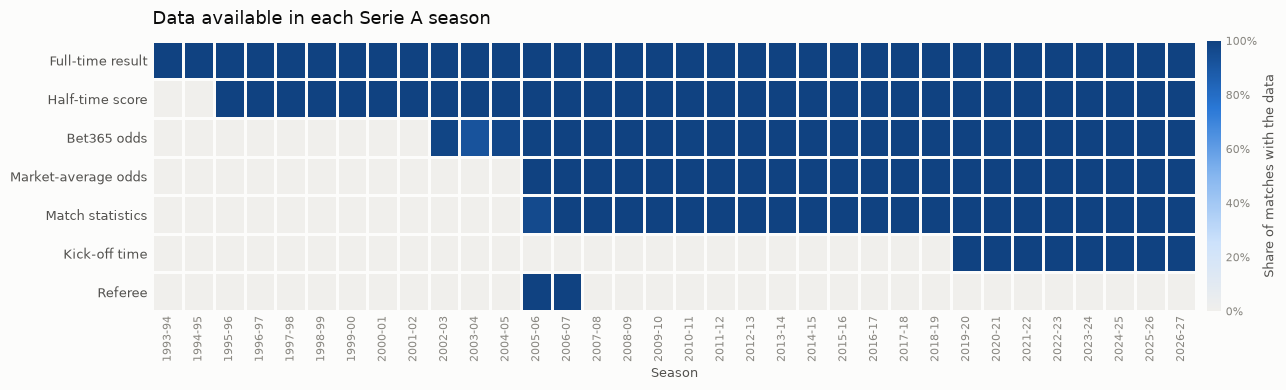

In [14]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
# Sequential single-hue ramp (light = no data, dark blue = every match has it)
coverage_cmap = LinearSegmentedColormap.from_list(
    "coverage", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
)

fig, ax = plt.subplots(figsize=(13, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
mesh = ax.pcolormesh(coverage.values, cmap=coverage_cmap, vmin=0, vmax=1,
                     edgecolors=SURFACE, linewidth=2)

ax.set_xticks([i + 0.5 for i in range(coverage.shape[1])],
              coverage.columns, rotation=90, fontsize=8, color=MUTED)
ax.set_yticks([i + 0.5 for i in range(coverage.shape[0])],
              coverage.index, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title("Data available in each Serie A season", loc="left", fontsize=13, color=INK, pad=12)
ax.set_xlabel("Season", color=INK_2, fontsize=9)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.01)
cbar.set_label("Share of matches with the data", color=INK_2, fontsize=9)
cbar.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
cbar.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cbar.outline.set_visible(False)

fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "01_data_coverage_by_season.png", dpi=150, facecolor=SURFACE)
plt.show()

In [15]:
first_full_season = {
    group: (row[row >= 0.99].index[0] if (row >= 0.99).any() else "never complete")
    for group, row in coverage.iterrows()
}
pd.Series(first_full_season, name="first season with complete data").to_frame()

,first season with complete data
Full-time result,1993-94
Half-time score,1995-96
Bet365 odds,2005-06
Market-average odds,2005-06
Match statistics,2006-07
Kick-off time,2019-20
Referee,2005-06


**What this means for modelling:**

- **Results-only features** (form, goals scored and conceded, points, head-to-head) can use all
  34 seasons, roughly 11,800 matches.
- **Match statistics** (shots, corners, cards) only exist from **2005-06**, so models using them
  are limited to about 8,000 matches.
- **Betting odds** make a strong benchmark: the bookmakers' implied probabilities are what our
  models have to beat. Bet365 odds go back to 2002-03 and market averages to 2005-06.
- Referee and kick-off time are too sparse to be useful features.

## 5. Save the processed dataset

In [16]:
path = save_matches(matches)
print(f"Saved {len(matches):,} matches to {path.relative_to(path.parents[2])}")

Saved 11,826 matches to data\processed\matches.csv


## Next steps

- **Commit 4:** cleaning checks and initial exploratory analysis: outcome distribution
  (how strong is home advantage?), goals per season, team histories.
- Later notebooks load this dataset with `src.preprocessing.load_matches()`, which restores the
  correct column types.